# Auswertung von Slugtests – Hvorslev und Bouwer-Rice

**Hydraulische Methoden · Hydrogeologie**

Dieses Notebook zeigt die Auswertung eines Slugtests mit zwei klassischen Verfahren. Die vorgegebenen Messwerte stammen aus **Messstelle 1 der Übungsaufgabe**. Beide Methoden verwenden eine halblogarithmische Anpassung der abklingenden Wasserspiegelauslenkung.

**Lernziele:** aus der Abklingkurve die charakteristische Zeit bestimmen, den Durchlässigkeitsbeiwert **K** berechnen und die geometrieabhängigen Ansätze beider Verfahren vergleichen.

*Notebook von Tanja Liesch, teilweise basierend auf Code von [Gert Ghysels](https://github.com/VUB-HYDR/slugtest) und [Karl DeBisschop](http://hydrotools.sourceforge.net/).*

## 1. Eingabedaten

Wir belassen die geometrischen Abmessungen zunächst in **ft** und rechnen die Ergebnisse erst am Ende von ft/s in m/s um. Die Zeitangaben sind in Sekunden. Mit **h₀ = 1 ft** entsprechen die gemessenen Auslenkungen zugleich den normierten Werten **h(t)/h₀**.

Die Eingaben sind hier zusammengefasst und werden in beiden Auswertungen verwendet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 100,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FT_TO_M = 0.3048

# Well geometry in feet / Brunnengeometrie in ft
rc = 0.083       # effective casing radius / effektiver Brunnenrohrradius
L = 9.0         # screen length / Filterlänge
rew = 0.25      # effective screen radius / effektiver Filterradius
Lw = 18.0       # distance to screen base / Tiefe bis Filterunterkante
M = 26.0        # saturated thickness / wassererfüllte Mächtigkeit

h0 = 1.0        # initial displacement / anfängliche Auslenkung [ft]
times = np.arange(15, dtype=float)  # [s]
h_obs = np.array([1, 0.78, 0.61, 0.48, 0.37, 0.29, 0.22, 0.17,
                  0.13, 0.10, 0.081, 0.062, 0.049, 0.039, 0.030])  # [ft]

assert np.all(h_obs > 0) and h0 > 0
assert len(times) == len(h_obs)
assert min(rc, rew, L, Lw, M) > 0

# Linear regression in log10(h/h0) vs. t / Lineare Regression
log_relative_h = np.log10(h_obs / h0)
slope, intercept = np.polyfit(times, log_relative_h, deg=1)
h_fit = h0 * 10**(slope * times + intercept)
rmse = np.sqrt(np.mean((h_obs - h_fit)**2))  # RMSE in ft


## 2. Hvorslev-Verfahren

Das Hvorslev-Verfahren nutzt den annähernd exponentiellen Rückgang der normierten Auslenkung **h(t)/h₀**. Im Diagramm wird die Zeit **t** linear und das Verhältnis **h(t)/h₀** logarithmisch dargestellt. Aus der Ausgleichsgeraden wird die Zeit **t₃₇** bestimmt, zu der die Auslenkung auf 37 % ihres Ausgangswerts gesunken ist.

Für die hier verwendete Brunnengeometrie gilt näherungsweise:

$$
K = \frac{r_c^2\,\ln(L/r_{ew})}{2L\,t_{37}}
$$

Dabei sind **r_c** der effektive Brunnenrohrradius, **r_ew** der effektive Filterradius und **L** die Filterlänge.

### 2.1 Messwerte und Regressionsgerade

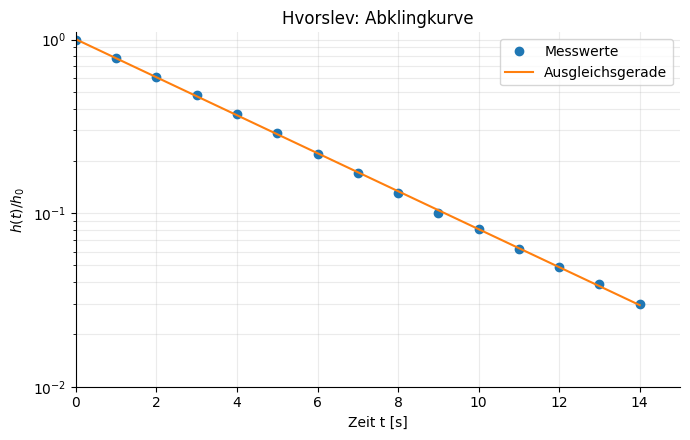

slope = -0.10939 log10-units/s, intercept = 0.00143
RMSE = 0.0035 ft (0.0011 m)


In [2]:
fig, ax = plt.subplots()
ax.semilogy(times, h_obs/h0, 'o', label='Messwerte')
ax.semilogy(times, h_fit/h0, '-', label='Ausgleichsgerade')
ax.set(xlabel='Zeit t [s]', ylabel=r'$h(t)/h_0$',
       title='Hvorslev: Abklingkurve')
ax.set_xlim(0, 15)
ax.set_ylim(1e-2, 1.1)
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"slope = {slope:.5f} log10-units/s, intercept = {intercept:.5f}")
print(f"RMSE = {rmse:.4f} ft ({rmse*FT_TO_M:.4f} m)")

### 2.2 Berechnung von t₃₇ und K

Die Regressionsgerade lautet **log₁₀(h/h₀) = m · t + c**. Für **h/h₀ = 0,37** ergibt sich **t₃₇**. Der berechnete Durchlässigkeitsbeiwert wird anschließend in m/s umgerechnet.

In [3]:
t37 = (np.log10(0.37) - intercept) / slope
K_hvorslev_fts = rc**2 * np.log(L/rew) / (2 * L * t37)
K_hvorslev_ms = K_hvorslev_fts * FT_TO_M
print(f"t37 = {t37:.2f} s")
print(f"K (Hvorslev) = {K_hvorslev_fts:.3e} ft/s = {K_hvorslev_ms:.3e} m/s")

t37 = 3.96 s
K (Hvorslev) = 3.463e-04 ft/s = 1.056e-04 m/s


## 3. Bouwer-Rice-Verfahren

Auch hier wird eine Gerade an den logarithmierten Verlauf von **h(t)** angepasst. Der Ansatz berücksichtigt die Brunneneinbaugeometrie über den dimensionslosen Ausdruck **ln(Rₑ/r_ew)**.

$$
K = \frac{r_c^2\,\ln(R_e/r_{ew})}{2L_e}\,\frac{1}{t}\,\ln\left(\frac{h_0}{h_t}\right)
$$

Hier bezeichnet **Lₑ** die Filterlänge. Der Quotient **ln(h₀/hₜ)/t** wird aus der angepassten Exponentialkurve gewonnen.

Für einen vollständig durchteuften Grundwasserleiter wird verwendet:

$$
\ln\left(\frac{R_e}{r_{ew}}\right)=\left[\frac{1.1}{\ln(L_w/r_{ew})}+\frac{C}{L_e/r_{ew}}\right]^{-1}
$$

Für einen unvollständig durchteuften Grundwasserleiter verwenden wir – entsprechend der Übungsaufgabe – folgende Näherung:

$$
\ln\left(\frac{R_e}{r_{ew}}\right)=\left[\frac{1.1}{\ln(L_w/r_{ew})}+\frac{A+B\ln((M-L_w)r_{ew})}{L_e/r_{ew}}\right]^{-1}
$$

Die empirischen Koeffizienten **A**, **B** und **C** werden mit den Näherungsfunktionen von DeBisschop berechnet. **Hinweis:** Die Originalimplementierung verwendet für die letzte Näherung die vorgegebenen Längeneinheiten der Übung; diese Konvention wird hier beibehalten.

### 3.1 Empirische Koeffizienten A, B und C

Wir übernehmen die stückweisen Näherungsfunktionen aus der Vorlage. Dabei ist **x = log₁₀(Lₑ/r_ew)**.

In [4]:
Le = L
x = np.log10(Le / rew)

if x < 2.554422663:
    A = 1.638445671 + 0.166908063*x + 0.000740459*np.exp(6.17105281*x - 1.054747686*x*x)
else:
    A = 11.00393028 - 170.7752217*np.exp(-1.509639982*x)

if x < 2.596774459:
    B = 0.174811819 + 0.060059188*x + 0.007965502*np.exp(2.053376868*x - 0.007790328*x*x)
else:
    B = 4.133124586 - 93.06136936*np.exp(-1.435370997*x)

if x < 2.200426117:
    C = 0.074711376 + 1.083958569*x + 0.00557352*np.exp(2.929493814*x - 0.001028433*x*x)
else:
    C = 15.66887372 - 178.4329289*np.exp(-1.322779744*x)

print(f"log10(Le/rew) = {x:.4f}")
print(f"A = {A:.3f}, B = {B:.3f}, C = {C:.3f}")

log10(Le/rew) = 1.5563
A = 2.751, B = 0.459, C = 2.293


### 3.2 Anpassung der Abklingkurve

Die Messdaten sind dieselben wie zuvor. Für den Bouwer-Rice-Ansatz wird **h(t)** direkt verwendet; bei **h₀ = 1 ft** unterscheidet sich der Zahlenwert allerdings nicht von **h(t)/h₀**.

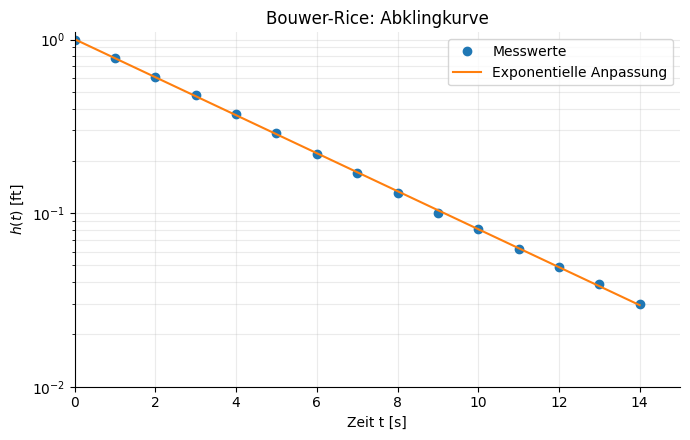

RMSE = 0.0035 ft (0.0011 m)


In [5]:
fig, ax = plt.subplots()
ax.semilogy(times, h_obs, 'o', label='Messwerte')
ax.semilogy(times, h_fit, '-', label='Exponentielle Anpassung')
ax.set(xlabel='Zeit t [s]', ylabel=r'$h(t)$ [ft]',
       title='Bouwer-Rice: Abklingkurve')
ax.set_xlim(0, 15)
ax.set_ylim(1e-2, 1.1)
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
print(f"RMSE = {rmse:.4f} ft ({rmse*FT_TO_M:.4f} m)")

### 3.3 Wert aus der Regressionsgeraden

Als Beispiel wählen wir **t = 10 s** und berechnen die zugehörige Auslenkung aus der Regressionsgeraden. Der Quotient **ln(h₀/hₜ)/t** ist bei einer exakt exponentiellen Abnahme mit Ursprungsauslenkung **h₀** zeitunabhängig. Da der angepasste Achsenabschnitt wegen der Messstreuung leicht von **h₀** abweicht, verwenden wir für die Berechnung konsistent zwei Werte der angepassten Kurve (bei **t = 0** und **t = 10 s**).

In [6]:
t_example = 10.0
h_fit_0 = 10**intercept       # fitted initial displacement [ft]
h_fit_t = 10**(slope*t_example + intercept)  # [ft]
rate = np.log(h_fit_0/h_fit_t) / t_example  # [1/s]
print(f"t = {t_example:g} s, h(t) = {h_fit_t:.3f} ft")
print(f"ln(h_fit(0)/h_fit(t))/t = {rate:.5f} 1/s")

t = 10 s, h(t) = 0.081 ft
ln(h_fit(0)/h_fit(t))/t = 0.25188 1/s


### 3.4 Effektiver Einflussradius für beide Geometrien

Wir berechnen **ln(Rₑ/r_ew)** sowohl für vollständige als auch unvollständige Durchteufung, um den Einfluss dieser Modellannahme zu vergleichen.

In [7]:
u_full = 1.0 / (1.1/np.log(Lw/rew) + C/(Le/rew))
u_partial = 1.0 / (1.1/np.log(Lw/rew) + (A + B*np.log((M-Lw)*rew))/(Le/rew))
print(f"ln(Re/rew), fully penetrating = {u_full:.5f}")
print(f"ln(Re/rew), partially penetrating = {u_partial:.5f}")

ln(Re/rew), fully penetrating = 3.11629
ln(Re/rew), partially penetrating = 2.91991


### 3.5 Berechnung von K

Mit der aus der Regressionsgeraden bestimmten Abklingrate berechnen wir **K** für beide Annahmen zur Brunnendurchteufung.

In [8]:
K_full_fts = rc**2 * u_full / (2 * Le) * rate
K_partial_fts = rc**2 * u_partial / (2 * Le) * rate
K_full_ms = K_full_fts * FT_TO_M
K_partial_ms = K_partial_fts * FT_TO_M
print(f"K (fully penetrating)     = {K_full_ms:.3e} m/s")
print(f"K (partially penetrating) = {K_partial_ms:.3e} m/s")

K (fully penetrating)     = 9.157e-05 m/s
K (partially penetrating) = 8.580e-05 m/s


## 4. Zusammenfassung und Einordnung

Beide Verfahren beruhen auf der annähernd exponentiellen Abnahme der Wasserspiegelauslenkung. Die unterschiedlichen geometrischen Annahmen wirken sich auf die berechnete hydraulische Durchlässigkeit aus. Beim Bouwer-Rice-Verfahren muss entsprechend der tatsächlichen Ausbau- und Aquifergeometrie die geeignete Formel gewählt werden.

Für die Interpretation sind insbesondere die korrekte Brunnengeometrie, die gewählte Modellannahme und eine annähernd geradlinige Abklingkurve im halblogarithmischen Diagramm entscheidend.

**Weiterführende Hinweise:** [Ghysels – Slugtest-Code](https://github.com/VUB-HYDR/slugtest); [DeBisschop – Hydrotools](http://hydrotools.sourceforge.net/).

In [9]:
print("Hvorslev:            K = %.3e m/s" % K_hvorslev_ms)
print("Bouwer-Rice (full):  K = %.3e m/s" % K_full_ms)
print("Bouwer-Rice (part):  K = %.3e m/s" % K_partial_ms)

Hvorslev:            K = 1.056e-04 m/s
Bouwer-Rice (full):  K = 9.157e-05 m/s
Bouwer-Rice (part):  K = 8.580e-05 m/s
